# RQ1第四步：Fully Connected Neural Network（FNN）轨迹模型

这份notebook沿用前面Multi-output Ridge的完整实验设计：每个case使用过去24小时的轨迹和速度，一次输出未来72小时完整轨迹。

- **输入完全相同**：起点经纬度 + 过去24小时的相对位置与速度，共98个特征；
- **输出完全相同**：未来72小时相对起点的东西、南北位移，共144个目标；
- **数据划分完全相同**：只用3,591个training cases学习模型，在training drifters内部选择网络配置；
- **Calibration set保留不用**：留给后续conformal prediction；
- **最终评价完全相同**：只在757个test cases上使用Haversine separation error。

FNN与Ridge的关键差别是加入隐藏层和ReLU非线性，因此它可以学习输入轨迹与未来运动之间的非线性关系。为了让notebook无需额外深度学习框架也能复现，网络训练、反向传播和Adam优化器均使用NumPy实现。

## 1. 模型定义

对一个case，输入向量为 $x\in\mathbb{R}^{98}$，输出为 $\hat y\in\mathbb{R}^{144}$。两层隐藏层FNN写成：

$$h_1=\operatorname{ReLU}(xW_1+b_1),$$

$$h_2=\operatorname{ReLU}(h_1W_2+b_2),$$

$$\hat y=h_2W_3+b_3.$$

这里的144个输出依次为未来第1至72小时的东向、北向位移。输出层不使用激活函数，因为位移既可以为正也可以为负。

训练损失为标准化目标上的均方误差加L2正则化：

$$\mathcal L=\frac{1}{nm}\sum_{i=1}^{n}\sum_{j=1}^{m}(\hat y_{ij}-y_{ij})^2+\lambda\sum_l\lVert W_l\rVert_F^2.$$

网络依然是参数模型；“非线性”来自隐藏层的ReLU，而不是说预测轨迹必须是某种固定形状。

In [1]:
from pathlib import Path
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'processed').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('找不到data/processed；请从项目目录或notebooks子目录打开。')

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'rq1' / 'zh'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6_371.0
HISTORY_HOURS = 24
HORIZON_HOURS = 72
N_FOLDS = 5
RANDOM_SEED = 3001

# 控制训练时间并降低过拟合风险。
MAX_EPOCHS = 180
PATIENCE = 20
BATCH_SIZE = 256
LEARNING_RATE = 1e-3

# 小型候选集同时比较网络容量与L2强度。
FNN_CONFIGS = [
    {'name': '64', 'hidden_sizes': (64,), 'l2': 1e-4},
    {'name': '128-64', 'hidden_sizes': (128, 64), 'l2': 1e-4},
    {'name': '128-64 stronger L2', 'hidden_sizes': (128, 64), 'l2': 1e-3},
]

plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('项目目录：', PROJECT_ROOT.resolve())
print('结果目录：', OUTPUT_DIR.resolve())

项目目录： /Users/roger/Documents/data3001-project-main
结果目录： /Users/roger/Documents/data3001-project-main/output/rq1/zh


## 2. 球面位置与局部位移转换

网络不直接预测绝对经纬度，而是预测相对于forecast origin的东向、北向位移（km）。这避免了直接对角度做回归，并使不同case的输出具有统一含义。最终再把预测位移转换回经纬度，用Haversine大圆距离评价。

In [2]:
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    lat1 = np.deg2rad(np.asarray(latitude, dtype=float))
    lon1 = np.deg2rad(np.asarray(longitude, dtype=float))
    dlon = (lon1 - lon0 + np.pi) % (2 * np.pi) - np.pi
    dlat = lat1 - lat0
    a = np.sin(dlat / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin(dlon / 2) ** 2
    central_angle = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(
        np.sin(dlon) * np.cos(lat1),
        np.cos(lat0) * np.sin(lat1) - np.sin(lat0) * np.cos(lat1) * np.cos(dlon),
    )
    distance_km = EARTH_RADIUS_KM * central_angle
    return distance_km * np.sin(bearing), distance_km * np.cos(bearing)


def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    east_km = np.asarray(east_km, dtype=float)
    north_km = np.asarray(north_km, dtype=float)
    distance_km = np.hypot(east_km, north_km)
    bearing = np.arctan2(east_km, north_km)
    angular_distance = distance_km / EARTH_RADIUS_KM
    latitude = np.arcsin(
        np.sin(lat0) * np.cos(angular_distance)
        + np.cos(lat0) * np.sin(angular_distance) * np.cos(bearing)
    )
    longitude = lon0 + np.arctan2(
        np.sin(bearing) * np.sin(angular_distance) * np.cos(lat0),
        np.cos(angular_distance) - np.sin(lat0) * np.sin(latitude),
    )
    return np.rad2deg(latitude), (np.rad2deg(longitude) + 180.0) % 360.0 - 180.0


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.deg2rad(np.asarray(lat1, dtype=float))
    lon1 = np.deg2rad(np.asarray(lon1, dtype=float))
    lat2 = np.deg2rad(np.asarray(lat2, dtype=float))
    lon2 = np.deg2rad(np.asarray(lon2, dtype=float))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

## 3. 读取固定cases并构造98维输入

这里不重新抽样，也不改变已经固定的training/calibration/test partition。每个case提取恰好24条历史观测；每小时包含相对东向位移、相对北向位移、$v_e$和$v_n$四个变量。

In [3]:
origins = (
    pd.read_parquet(PROCESSED / 'forecast_origins.parquet')
    .sort_values('forecast_case_id').reset_index(drop=True)
)
observations = pd.read_parquet(
    PROCESSED / 'region_A_observations.parquet',
    columns=['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude', 've', 'vn'],
)
n_cases = len(origins)

history = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'history_start_step',
    'origin_latitude', 'origin_longitude',
]].loc[origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
history['history_index'] = np.tile(np.arange(HISTORY_HOURS), n_cases)
history['segment_step'] = history['history_start_step'] + history['history_index']
history = history.merge(
    observations, on=['ID', 'segment_id', 'segment_step'],
    how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'history_index']).reset_index(drop=True)

history['relative_east_km'], history['relative_north_km'] = latlon_to_local_km(
    history['origin_latitude'], history['origin_longitude'],
    history['latitude'], history['longitude'],
)
history_values = history[[
    'relative_east_km', 'relative_north_km', 've', 'vn',
]].to_numpy().reshape(n_cases, HISTORY_HOURS, 4)

X = np.column_stack([
    origins['origin_latitude'].to_numpy(),
    origins['origin_longitude'].to_numpy(),
    history_values.reshape(n_cases, -1),
]).astype(np.float64)

history_checks = pd.Series({
    '全部cases数量为5117': n_cases == 5117,
    '每个case恰好24条历史观测': history.groupby('forecast_case_id').size().eq(24).all(),
    '输入矩阵形状为5117×98': X.shape == (5117, 98),
    '输入没有缺失或无限值': np.isfinite(X).all(),
}, name='是否通过')
display(history_checks.to_frame())
assert history_checks.all()

,是否通过
全部cases数量为5117,True
每个case恰好24条历史观测,True
输入矩阵形状为5117×98,True
输入没有缺失或无限值,True


## 4. 构造未来72小时的144维目标

未来每个时刻包含东向和北向两个位移，因此目标矩阵形状为 $5,117\times(72\times2)=5,117\times144$。

In [4]:
targets = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'target_start_step',
    'origin_latitude', 'origin_longitude',
]].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
targets['lead_time_hours'] = np.tile(np.arange(1, HORIZON_HOURS + 1), n_cases)
targets['segment_step'] = targets['target_start_step'] + targets['lead_time_hours'] - 1
targets = targets.merge(
    observations[['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude']],
    on=['ID', 'segment_id', 'segment_step'], how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'lead_time_hours']).reset_index(drop=True)

targets['target_east_km'], targets['target_north_km'] = latlon_to_local_km(
    targets['origin_latitude'], targets['origin_longitude'],
    targets['latitude'], targets['longitude'],
)
Y = targets[['target_east_km', 'target_north_km']].to_numpy().reshape(
    n_cases, HORIZON_HOURS * 2
).astype(np.float64)

target_checks = pd.Series({
    '每个case恰好72条未来观测': targets.groupby('forecast_case_id').size().eq(72).all(),
    '目标矩阵形状为5117×144': Y.shape == (5117, 144),
    '目标没有缺失或无限值': np.isfinite(Y).all(),
}, name='是否通过')
display(target_checks.to_frame())
assert target_checks.all()

,是否通过
每个case恰好72条未来观测,True
目标矩阵形状为5117×144,True
目标没有缺失或无限值,True


## 5. 只在training drifters内部建立5折交叉验证

同一条drifter产生的所有cases始终属于同一个fold，防止同一条真实轨迹同时出现在训练和验证中。Calibration和test完全不参与网络结构、L2强度或训练轮数的选择。

In [5]:
train_indices = np.flatnonzero(origins['partition'].eq('training').to_numpy())
calibration_indices = np.flatnonzero(origins['partition'].eq('calibration').to_numpy())
test_indices = np.flatnonzero(origins['partition'].eq('test').to_numpy())

training_group_counts = origins.loc[train_indices].groupby('ID').size().sort_values(ascending=False)
fold_drifters = [[] for _ in range(N_FOLDS)]
fold_case_counts = np.zeros(N_FOLDS, dtype=int)
for drifter_id, count in training_group_counts.items():
    fold = int(np.argmin(fold_case_counts))
    fold_drifters[fold].append(drifter_id)
    fold_case_counts[fold] += int(count)

fold_summary = pd.DataFrame({
    'Fold': np.arange(1, N_FOLDS + 1),
    'Training drifters held out': [len(x) for x in fold_drifters],
    'Validation cases': fold_case_counts,
})
display(fold_summary)

assert len(train_indices) == 3591
assert len(calibration_indices) == 769
assert len(test_indices) == 757
assert fold_case_counts.sum() == len(train_indices)

,Fold,Training drifters held out,Validation cases
0,1,63,719
1,2,62,718
2,3,62,718
3,4,62,718
4,5,62,718


## 6. 使用NumPy实现FNN与Adam优化器

每次拟合只用当前fold的训练部分计算输入、输出均值和标准差。Early stopping监控该fold的验证误差，并保存验证误差最低时的参数。

这里输出也要标准化：未来72小时的位移尺度明显不同，如果直接训练，较远lead times会因为数值更大而主导损失。

In [6]:
def relu(x):
    return np.maximum(x, 0.0)


def initialise_parameters(layer_sizes, rng):
    parameters = []
    for fan_in, fan_out in zip(layer_sizes[:-1], layer_sizes[1:]):
        # ReLU隐藏层使用He initialization；输出层也采用稳定的小尺度初始化。
        scale = np.sqrt(2.0 / fan_in)
        parameters.append({
            'W': rng.normal(0.0, scale, size=(fan_in, fan_out)),
            'b': np.zeros(fan_out),
        })
    return parameters


def forward(parameters, X_batch):
    activations = [X_batch]
    pre_activations = []
    current = X_batch
    for layer_number, layer in enumerate(parameters):
        z = current @ layer['W'] + layer['b']
        pre_activations.append(z)
        current = relu(z) if layer_number < len(parameters) - 1 else z
        activations.append(current)
    return current, activations, pre_activations


def loss_and_gradients(parameters, X_batch, Y_batch, l2):
    prediction, activations, pre_activations = forward(parameters, X_batch)
    residual = prediction - Y_batch
    mse = np.mean(np.square(residual))
    penalty = l2 * sum(np.sum(np.square(layer['W'])) for layer in parameters)

    delta = 2.0 * residual / residual.size
    gradients = [None] * len(parameters)
    for layer_number in range(len(parameters) - 1, -1, -1):
        gradients[layer_number] = {
            'W': activations[layer_number].T @ delta + 2.0 * l2 * parameters[layer_number]['W'],
            'b': delta.sum(axis=0),
        }
        if layer_number > 0:
            delta = (delta @ parameters[layer_number]['W'].T) * (
                pre_activations[layer_number - 1] > 0
            )
    return mse + penalty, gradients


def predict_standardised(parameters, X_standard):
    return forward(parameters, X_standard)[0]


def fit_fnn(X_train, Y_train, X_valid, Y_valid, hidden_sizes, l2, seed,
            max_epochs=MAX_EPOCHS, patience=PATIENCE, verbose=False):
    x_mean = X_train.mean(axis=0)
    x_scale = X_train.std(axis=0)
    x_scale[x_scale < 1e-12] = 1.0
    y_mean = Y_train.mean(axis=0)
    y_scale = Y_train.std(axis=0)
    y_scale[y_scale < 1e-12] = 1.0

    Xtr = (X_train - x_mean) / x_scale
    Ytr = (Y_train - y_mean) / y_scale
    Xva = (X_valid - x_mean) / x_scale

    rng = np.random.default_rng(seed)
    parameters = initialise_parameters((X.shape[1], *hidden_sizes, Y.shape[1]), rng)
    first_moment = [
        {'W': np.zeros_like(p['W']), 'b': np.zeros_like(p['b'])} for p in parameters
    ]
    second_moment = copy.deepcopy(first_moment)
    beta1, beta2, epsilon = 0.9, 0.999, 1e-8
    step = 0
    best_rmse = np.inf
    best_parameters = None
    best_epoch = 0
    epochs_without_improvement = 0
    history_rows = []

    for epoch in range(1, max_epochs + 1):
        permutation = rng.permutation(len(Xtr))
        batch_losses = []
        for start in range(0, len(Xtr), BATCH_SIZE):
            batch = permutation[start:start + BATCH_SIZE]
            loss, gradients = loss_and_gradients(parameters, Xtr[batch], Ytr[batch], l2)
            batch_losses.append(loss)
            step += 1
            for layer_number, (layer, gradient) in enumerate(zip(parameters, gradients)):
                for key in ('W', 'b'):
                    first_moment[layer_number][key] = (
                        beta1 * first_moment[layer_number][key] + (1 - beta1) * gradient[key]
                    )
                    second_moment[layer_number][key] = (
                        beta2 * second_moment[layer_number][key] + (1 - beta2) * np.square(gradient[key])
                    )
                    m_hat = first_moment[layer_number][key] / (1 - beta1 ** step)
                    v_hat = second_moment[layer_number][key] / (1 - beta2 ** step)
                    layer[key] -= LEARNING_RATE * m_hat / (np.sqrt(v_hat) + epsilon)

        valid_standard = predict_standardised(parameters, Xva)
        valid_prediction = valid_standard * y_scale + y_mean
        valid_rmse = float(np.sqrt(np.mean(np.square(valid_prediction - Y_valid))))
        history_rows.append({
            'epoch': epoch,
            'training_objective': float(np.mean(batch_losses)),
            'validation_displacement_rmse_km': valid_rmse,
        })

        if valid_rmse < best_rmse - 1e-5:
            best_rmse = valid_rmse
            best_epoch = epoch
            best_parameters = copy.deepcopy(parameters)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose and (epoch == 1 or epoch % 25 == 0):
            print(f'epoch={epoch:3d}, validation RMSE={valid_rmse:.3f} km')
        if epochs_without_improvement >= patience:
            break

    return {
        'hidden_sizes': tuple(hidden_sizes), 'l2': float(l2),
        'x_mean': x_mean, 'x_scale': x_scale,
        'y_mean': y_mean, 'y_scale': y_scale,
        'parameters': best_parameters, 'best_epoch': best_epoch,
        'best_validation_rmse_km': best_rmse,
        'history': pd.DataFrame(history_rows),
    }


def predict_fnn(model, X_new):
    X_standard = (X_new - model['x_mean']) / model['x_scale']
    prediction_standard = predict_standardised(model['parameters'], X_standard)
    return prediction_standard * model['y_scale'] + model['y_mean']

## 7. 在training内部选择网络配置

比较三个预先设定的候选配置：一个较小的单隐藏层网络，以及两个L2强度不同的两隐藏层网络。每个配置在完全相同的5个grouped folds上评估。

选择指标是144个未来位移坐标的validation RMSE。这里的validation folds属于training partition内部，**不是**单独保留的calibration set。

In [7]:
cv_rows = []
cv_histories = []
training_start = time.time()

for config_number, config in enumerate(FNN_CONFIGS):
    print(f"\n配置 {config['name']}，hidden={config['hidden_sizes']}，L2={config['l2']:g}")
    for fold_number, validation_drifters in enumerate(fold_drifters, start=1):
        is_validation = origins.loc[train_indices, 'ID'].isin(validation_drifters).to_numpy()
        fold_validation_indices = train_indices[is_validation]
        fold_training_indices = train_indices[~is_validation]
        model = fit_fnn(
            X[fold_training_indices], Y[fold_training_indices],
            X[fold_validation_indices], Y[fold_validation_indices],
            hidden_sizes=config['hidden_sizes'], l2=config['l2'],
            seed=RANDOM_SEED + 100 * config_number + fold_number,
        )
        cv_rows.append({
            'config': config['name'],
            'hidden_sizes': str(config['hidden_sizes']),
            'l2': config['l2'],
            'fold': fold_number,
            'validation_cases': len(fold_validation_indices),
            'best_epoch': model['best_epoch'],
            'validation_displacement_rmse_km': model['best_validation_rmse_km'],
        })
        fold_history = model['history'].copy()
        fold_history['config'] = config['name']
        fold_history['fold'] = fold_number
        cv_histories.append(fold_history)
        print(
            f"  Fold {fold_number}: epoch {model['best_epoch']}, "
            f"validation RMSE={model['best_validation_rmse_km']:.3f} km"
        )

cv_folds = pd.DataFrame(cv_rows)
cv_history = pd.concat(cv_histories, ignore_index=True)
cv_results = (
    cv_folds.groupby(['config', 'hidden_sizes', 'l2'], sort=False)
    .agg(
        mean_cv_rmse_km=('validation_displacement_rmse_km', 'mean'),
        std_cv_rmse_km=('validation_displacement_rmse_km', 'std'),
        median_best_epoch=('best_epoch', 'median'),
    )
    .reset_index()
)
best_row = cv_results.loc[cv_results['mean_cv_rmse_km'].idxmin()]
best_config = next(c for c in FNN_CONFIGS if c['name'] == best_row['config'])
selected_epochs = int(round(best_row['median_best_epoch']))

display(cv_results.round(3))
print('选择的配置：', best_config)
print('最终训练轮数（五折best epoch中位数）：', selected_epochs)
print(f'交叉验证耗时：{time.time() - training_start:.1f}秒')


配置 64，hidden=(64,)，L2=0.0001


  Fold 1: epoch 175, validation RMSE=26.845 km


  Fold 2: epoch 147, validation RMSE=26.915 km


  Fold 3: epoch 176, validation RMSE=26.405 km


  Fold 4: epoch 180, validation RMSE=28.858 km


  Fold 5: epoch 174, validation RMSE=25.883 km

配置 128-64，hidden=(128, 64)，L2=0.0001


... (8 outputs left out)

  Fold 4: epoch 111, validation RMSE=28.659 km


  Fold 5: epoch 132, validation RMSE=25.098 km


,config,hidden_sizes,l2,mean_cv_rmse_km,std_cv_rmse_km,median_best_epoch
0,64,"(64,)",0.000,26.981,1.127,175.0
1,128-64,"(128, 64)",0.000,26.710,1.265,87.0
2,128-64 stronger L2,"(128, 64)",0.001,26.399,1.342,129.0


选择的配置： {'name': '128-64 stronger L2', 'hidden_sizes': (128, 64), 'l2': 0.001}
最终训练轮数（五折best epoch中位数）： 129
交叉验证耗时：15.0秒


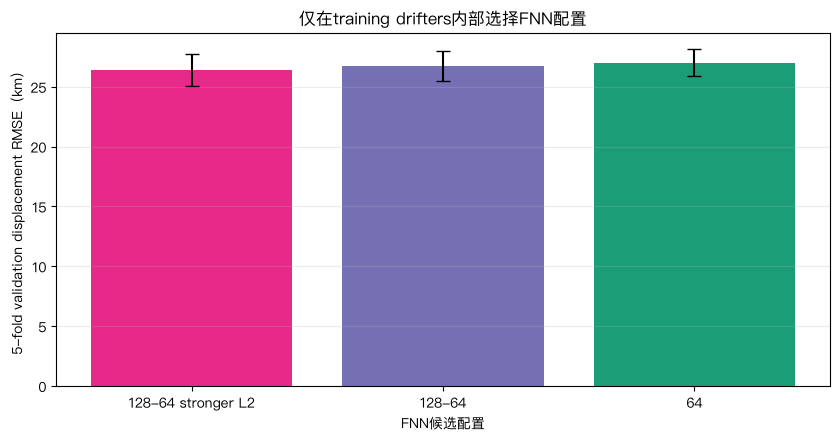

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_data = cv_results.sort_values('mean_cv_rmse_km')
ax.bar(
    plot_data['config'], plot_data['mean_cv_rmse_km'],
    yerr=plot_data['std_cv_rmse_km'], capsize=5, color=['#e7298a', '#7570b3', '#1b9e77'],
)
ax.set(
    xlabel='FNN候选配置', ylabel='5-fold validation displacement RMSE（km）',
    title='仅在training drifters内部选择FNN配置',
)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fnn_cross_validation.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. 使用全部training cases拟合最终FNN

交叉验证已经确定网络结构、L2强度和训练轮数。最终模型使用全部3,591个training cases训练固定轮数，不再查看calibration或test误差来决定何时停止。

In [9]:
def fit_final_fnn(X_train, Y_train, hidden_sizes, l2, epochs, seed):
    x_mean = X_train.mean(axis=0)
    x_scale = X_train.std(axis=0)
    x_scale[x_scale < 1e-12] = 1.0
    y_mean = Y_train.mean(axis=0)
    y_scale = Y_train.std(axis=0)
    y_scale[y_scale < 1e-12] = 1.0
    Xtr = (X_train - x_mean) / x_scale
    Ytr = (Y_train - y_mean) / y_scale

    rng = np.random.default_rng(seed)
    parameters = initialise_parameters((X.shape[1], *hidden_sizes, Y.shape[1]), rng)
    first_moment = [{'W': np.zeros_like(p['W']), 'b': np.zeros_like(p['b'])} for p in parameters]
    second_moment = copy.deepcopy(first_moment)
    beta1, beta2, epsilon = 0.9, 0.999, 1e-8
    step = 0
    training_losses = []

    for epoch in range(1, epochs + 1):
        permutation = rng.permutation(len(Xtr))
        epoch_losses = []
        for start in range(0, len(Xtr), BATCH_SIZE):
            batch = permutation[start:start + BATCH_SIZE]
            loss, gradients = loss_and_gradients(parameters, Xtr[batch], Ytr[batch], l2)
            epoch_losses.append(loss)
            step += 1
            for layer_number, (layer, gradient) in enumerate(zip(parameters, gradients)):
                for key in ('W', 'b'):
                    first_moment[layer_number][key] = beta1 * first_moment[layer_number][key] + (1-beta1) * gradient[key]
                    second_moment[layer_number][key] = beta2 * second_moment[layer_number][key] + (1-beta2) * np.square(gradient[key])
                    m_hat = first_moment[layer_number][key] / (1-beta1**step)
                    v_hat = second_moment[layer_number][key] / (1-beta2**step)
                    layer[key] -= LEARNING_RATE * m_hat / (np.sqrt(v_hat) + epsilon)
        training_losses.append(float(np.mean(epoch_losses)))

    return {
        'hidden_sizes': tuple(hidden_sizes), 'l2': float(l2), 'epochs': int(epochs),
        'x_mean': x_mean, 'x_scale': x_scale, 'y_mean': y_mean, 'y_scale': y_scale,
        'parameters': parameters, 'training_losses': np.array(training_losses),
    }


final_model = fit_final_fnn(
    X[train_indices], Y[train_indices],
    hidden_sizes=best_config['hidden_sizes'], l2=best_config['l2'],
    epochs=selected_epochs, seed=RANDOM_SEED + 999,
)
test_predictions = predict_fnn(final_model, X[test_indices]).reshape(
    len(test_indices), HORIZON_HOURS, 2
)
print('最终网络：', final_model['hidden_sizes'])
print('最终训练轮数：', final_model['epochs'])
print('测试预测矩阵：', test_predictions.shape)

最终网络： (128, 64)
最终训练轮数： 129
测试预测矩阵： (757, 72, 2)


## 9. 转回经纬度并计算测试集误差

模型在训练完成后被冻结，只对757个test cases做一次最终预测。每个未来时刻都计算预测位置和真实位置之间的Haversine separation error。

In [10]:
test_origins = origins.loc[test_indices].reset_index(drop=True)
origin_latitudes = np.repeat(test_origins['origin_latitude'].to_numpy(), HORIZON_HOURS)
origin_longitudes = np.repeat(test_origins['origin_longitude'].to_numpy(), HORIZON_HOURS)
predicted_latitude, predicted_longitude = local_km_to_latlon(
    origin_latitudes, origin_longitudes,
    test_predictions[:, :, 0].reshape(-1),
    test_predictions[:, :, 1].reshape(-1),
)

test_target_mask = targets['forecast_case_id'].isin(test_origins['forecast_case_id'])
test_targets = targets.loc[test_target_mask].sort_values(
    ['forecast_case_id', 'lead_time_hours']
).reset_index(drop=True)

evaluation = pd.DataFrame({
    'forecast_case_id': np.repeat(test_origins['forecast_case_id'].to_numpy(), HORIZON_HOURS),
    'ID': np.repeat(test_origins['ID'].to_numpy(), HORIZON_HOURS),
    'lead_time_hours': np.tile(np.arange(1, HORIZON_HOURS + 1), len(test_origins)),
    'origin_latitude': origin_latitudes,
    'origin_longitude': origin_longitudes,
    'predicted_east_km': test_predictions[:, :, 0].reshape(-1),
    'predicted_north_km': test_predictions[:, :, 1].reshape(-1),
    'pred_latitude': predicted_latitude,
    'pred_longitude': predicted_longitude,
    'true_latitude': test_targets['latitude'].to_numpy(),
    'true_longitude': test_targets['longitude'].to_numpy(),
})
evaluation['separation_error_km'] = haversine_km(
    evaluation['pred_latitude'], evaluation['pred_longitude'],
    evaluation['true_latitude'], evaluation['true_longitude'],
)

checks = pd.Series({
    '只评价757个test cases': evaluation['forecast_case_id'].nunique() == 757,
    '每个test case恰好72个lead times': evaluation.groupby('forecast_case_id').size().eq(72).all(),
    '全部误差均为有限数值': np.isfinite(evaluation['separation_error_km']).all(),
    'Calibration cases仍未用于拟合': len(calibration_indices) == 769,
}, name='是否通过')
display(checks.to_frame())
assert checks.all()

,是否通过
只评价757个test cases,True
每个test case恰好72个lead times,True
全部误差均为有限数值,True
Calibration cases仍未用于拟合,True


## 10. 测试集误差随lead time增长

深色曲线是757个test cases在每个lead time上的中位separation error；阴影是25%至75%分位区间，并不是最小值到最大值。

,lead_time_hours,n,median_error_km,mean_error_km,q25_error_km,q75_error_km,rmse_km
0,1,757,0.34,0.45,0.20,0.56,0.61
5,6,757,2.67,3.22,1.59,4.13,3.99
11,12,757,5.54,6.91,3.36,9.03,8.71
23,24,757,11.32,14.36,6.52,18.79,18.15
47,48,757,26.10,32.09,14.59,42.59,40.21
71,72,757,41.72,50.12,23.06,66.21,62.15


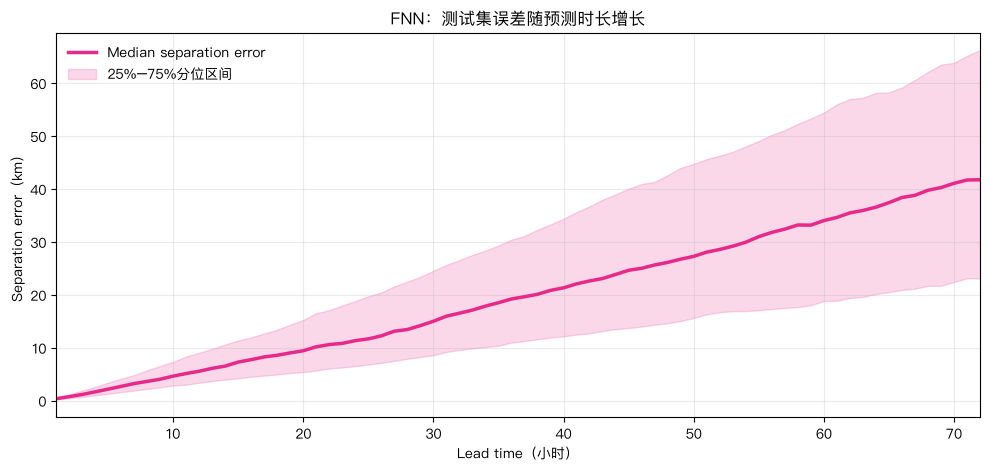

In [11]:
lead_metrics = (
    evaluation.groupby('lead_time_hours')['separation_error_km']
    .agg(
        n='size', median_error_km='median', mean_error_km='mean',
        q25_error_km=lambda x: x.quantile(0.25),
        q75_error_km=lambda x: x.quantile(0.75),
        rmse_km=lambda x: np.sqrt(np.mean(np.square(x))),
    ).reset_index()
)
display(lead_metrics[lead_metrics['lead_time_hours'].isin([1, 6, 12, 24, 48, 72])].round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
x = lead_metrics['lead_time_hours'].to_numpy()
median = lead_metrics['median_error_km'].to_numpy()
q25 = lead_metrics['q25_error_km'].to_numpy()
q75 = lead_metrics['q75_error_km'].to_numpy()
ax.plot(x, median, color='#e7298a', linewidth=2.5, label='Median separation error')
ax.fill_between(x, q25, q75, color='#e7298a', alpha=0.18, label='25%–75%分位区间')
ax.set(
    xlabel='Lead time（小时）', ylabel='Separation error（km）',
    title='FNN：测试集误差随预测时长增长',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fnn_error_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## 11. 与Ridge和两个baselines公平比较

四种方法使用相同的test cases、lead times和Haversine函数。FNN相对于某个参照模型的RMSE skill定义为：

$$\mathrm{Skill}=1-\frac{\mathrm{RMSE}_{\mathrm{FNN}}}{\mathrm{RMSE}_{\mathrm{reference}}}.$$

Skill大于0表示FNN误差更低，skill小于0表示FNN更差。

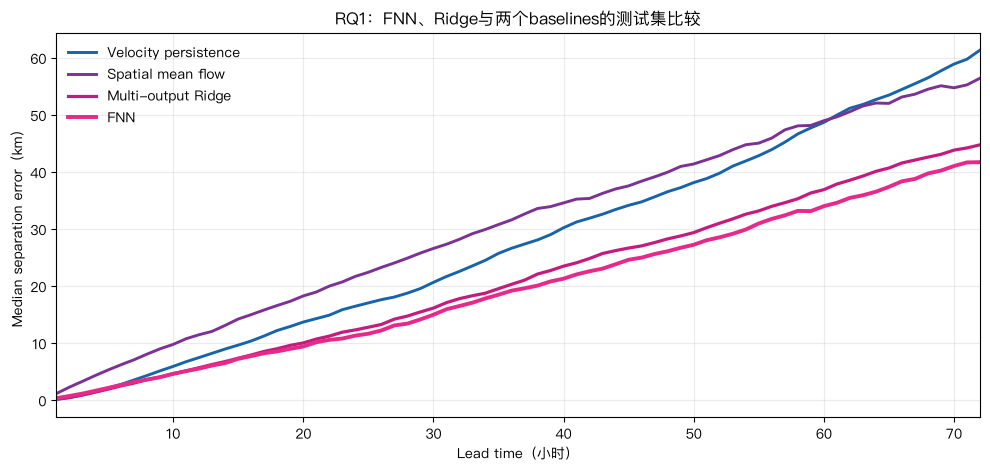

,fnn_median_km,ridge_median_km,persistence_median_km,mean_flow_median_km,fnn_rmse_km,ridge_rmse_km,persistence_rmse_km,mean_flow_rmse_km,fnn_rmse_minus_ridge_km,skill_vs_ridge_pct,skill_vs_persistence_pct,skill_vs_mean_flow_pct
lead_time_hours,,,,,,,,,,,,
24,11.32,12.32,16.47,21.69,18.15,18.97,24.07,29.87,-0.82,4.32,24.57,39.22
48,26.10,28.27,36.54,39.96,40.21,42.59,55.17,57.27,-2.38,5.58,27.12,29.79
72,41.72,44.75,61.35,56.42,62.15,65.91,90.10,80.98,-3.76,5.71,31.02,23.25


In [12]:
persistence_metrics = pd.read_csv(OUTPUT_DIR / 'velocity_persistence_lead_metrics.csv')
mean_flow_metrics = pd.read_csv(OUTPUT_DIR / 'spatial_mean_flow_lead_metrics.csv')
ridge_metrics = pd.read_csv(OUTPUT_DIR / 'ridge_lead_metrics.csv')

comparison = lead_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
    'median_error_km': 'fnn_median_km', 'rmse_km': 'fnn_rmse_km',
})
for name, frame in [
    ('persistence', persistence_metrics), ('mean_flow', mean_flow_metrics), ('ridge', ridge_metrics),
]:
    comparison = comparison.merge(
        frame[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
            'median_error_km': f'{name}_median_km', 'rmse_km': f'{name}_rmse_km',
        }), on='lead_time_hours', validate='one_to_one',
    )
    comparison[f'fnn_rmse_minus_{name}_km'] = comparison['fnn_rmse_km'] - comparison[f'{name}_rmse_km']
    comparison[f'skill_vs_{name}_pct'] = 100 * (1 - comparison['fnn_rmse_km'] / comparison[f'{name}_rmse_km'])

fig, ax = plt.subplots(figsize=(10, 4.8))
for column, label, color, width in [
    ('persistence_median_km', 'Velocity persistence', '#1764ab', 2.1),
    ('mean_flow_median_km', 'Spatial mean flow', '#7b3294', 2.1),
    ('ridge_median_km', 'Multi-output Ridge', '#c51b7d', 2.3),
    ('fnn_median_km', 'FNN', '#e7298a', 2.8),
]:
    ax.plot(comparison['lead_time_hours'], comparison[column], linewidth=width, color=color, label=label)
ax.set(
    xlabel='Lead time（小时）', ylabel='Median separation error（km）',
    title='RQ1：FNN、Ridge与两个baselines的测试集比较',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'rq1_four_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

comparison_table = comparison.loc[
    comparison['lead_time_hours'].isin([24, 48, 72]),
    [
        'lead_time_hours', 'fnn_median_km', 'ridge_median_km',
        'persistence_median_km', 'mean_flow_median_km',
        'fnn_rmse_km', 'ridge_rmse_km', 'persistence_rmse_km', 'mean_flow_rmse_km',
        'fnn_rmse_minus_ridge_km', 'skill_vs_ridge_pct',
        'skill_vs_persistence_pct', 'skill_vs_mean_flow_pct',
    ],
].set_index('lead_time_hours')
display(comparison_table.round(2))

## 12. Case-level integrated trajectory error与最终汇总

ITE是每个case从0至72小时的separation error曲线下面积，反映整条预测轨迹的累计误差，而不只是72小时终点误差。单位为km·h，数值越小越好。

In [13]:
def case_metrics(group):
    ordered = group.sort_values('lead_time_hours')
    errors = ordered['separation_error_km'].to_numpy()
    hours = ordered['lead_time_hours'].to_numpy()
    ite = np.trapezoid(np.r_[0.0, errors], x=np.r_[0, hours])
    return pd.Series({
        'integrated_trajectory_error_km_h': ite,
        'final_72h_error_km': errors[-1],
        'mean_trajectory_error_km': errors.mean(),
    })

test_case_metrics = evaluation.groupby('forecast_case_id', sort=False).apply(
    case_metrics, include_groups=False
).reset_index()

def metric_at(hour, column):
    return float(lead_metrics.loc[lead_metrics['lead_time_hours'].eq(hour), column].iloc[0])

summary = pd.DataFrame({
    '指标': [
        'Selected configuration', 'Selected L2', 'Selected epochs',
        'Training cases', 'Calibration cases (unused)', 'Test cases',
        '24h median error (km)', '48h median error (km)', '72h median error (km)',
        '72h RMSE (km)', 'Median ITE (km·h)',
    ],
    '结果': [
        best_config['name'], best_config['l2'], selected_epochs,
        len(train_indices), len(calibration_indices), len(test_indices),
        metric_at(24, 'median_error_km'), metric_at(48, 'median_error_km'),
        metric_at(72, 'median_error_km'), metric_at(72, 'rmse_km'),
        test_case_metrics['integrated_trajectory_error_km_h'].median(),
    ],
})
display(summary)

,指标,结果
0,Selected configuration,128-64 stronger L2
1,Selected L2,0.001
2,Selected epochs,129
3,Training cases,3591
4,Calibration cases (unused),769
5,Test cases,757
6,24h median error (km),11.316341
7,48h median error (km),26.102218
8,72h median error (km),41.715535
9,72h RMSE (km),62.149823


## 13. 代表性测试轨迹

选择FNN的72小时终点误差最接近测试集中位数的case，避免只展示最好或最差案例。黑色星号是forecast origin；绿色是真实未来轨迹；粉色是FNN预测。

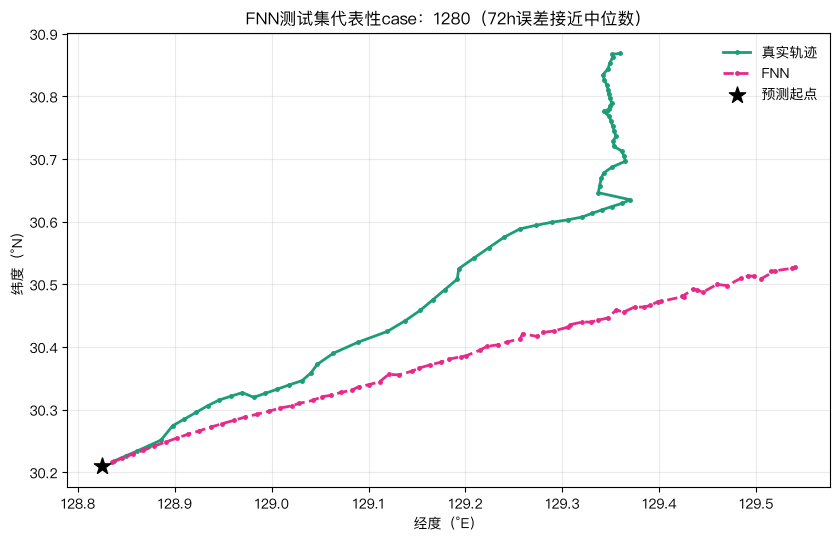

In [14]:
median_final = test_case_metrics['final_72h_error_km'].median()
example_id = test_case_metrics.loc[
    (test_case_metrics['final_72h_error_km'] - median_final).abs().idxmin(),
    'forecast_case_id',
]
example = evaluation[evaluation['forecast_case_id'].eq(example_id)].sort_values('lead_time_hours')

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(example['true_longitude'], example['true_latitude'], '-o', markersize=2.5,
        linewidth=2, color='#1b9e77', label='真实轨迹')
ax.plot(example['pred_longitude'], example['pred_latitude'], '--o', markersize=2.5,
        linewidth=2, color='#e7298a', label='FNN')
ax.scatter(example['origin_longitude'].iloc[0], example['origin_latitude'].iloc[0],
           marker='*', s=150, color='black', label='预测起点', zorder=5)
ax.set(
    xlabel='经度（°E）', ylabel='纬度（°N）',
    title=f'FNN测试集代表性case：{int(example_id)}（72h误差接近中位数）',
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fnn_example_trajectory.png', dpi=200, bbox_inches='tight')
plt.show()

## 14. 保存可复现结果

保存交叉验证结果、逐lead-time指标、case-level指标、模型参数以及poster可用图。模型参数中同时保存标准化参数和每一层的权重、偏置。

In [15]:
cv_folds.to_csv(OUTPUT_DIR / 'fnn_cross_validation_folds.csv', index=False)
cv_results.to_csv(OUTPUT_DIR / 'fnn_cross_validation_summary.csv', index=False)
cv_history.to_csv(OUTPUT_DIR / 'fnn_training_histories.csv', index=False)
lead_metrics.to_csv(OUTPUT_DIR / 'fnn_lead_metrics.csv', index=False)
test_case_metrics.to_csv(OUTPUT_DIR / 'fnn_test_case_metrics.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'rq1_four_model_comparison.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'fnn_summary.csv', index=False)

parameter_archive = {
    'hidden_sizes': np.array(final_model['hidden_sizes']),
    'l2': np.array(final_model['l2']),
    'epochs': np.array(final_model['epochs']),
    'x_mean': final_model['x_mean'], 'x_scale': final_model['x_scale'],
    'y_mean': final_model['y_mean'], 'y_scale': final_model['y_scale'],
}
for layer_number, layer in enumerate(final_model['parameters'], start=1):
    parameter_archive[f'W{layer_number}'] = layer['W']
    parameter_archive[f'b{layer_number}'] = layer['b']
np.savez_compressed(OUTPUT_DIR / 'fnn_model_parameters.npz', **parameter_archive)

saved_files = sorted(
    [p.name for p in OUTPUT_DIR.glob('fnn_*')]
    + [p.name for p in OUTPUT_DIR.glob('rq1_four_model_*')]
)
print('已保存：')
for name in saved_files:
    print(' -', name)

已保存：
 - fnn_cross_validation.png
 - fnn_cross_validation_folds.csv
 - fnn_cross_validation_summary.csv
 - fnn_error_curve.png
 - fnn_example_trajectory.png
 - fnn_lead_metrics.csv
 - fnn_model_parameters.npz
 - fnn_summary.csv
 - fnn_test_case_metrics.csv
 - fnn_training_histories.csv
 - rq1_four_model_comparison.csv
 - rq1_four_model_comparison.png
